# A01 — Pré-processamento do ressequenciamento (réplica do original)

## Objetivo

Aplicar às 14 bibliotecas ressequenciadas **exatamente** o pré-processamento
de `src/scripts/preprocessing.ipynb`, registrar o que cada etapa fez e
comparar com a corrida antiga. A avaliação de se falta pré-processamento
fica em A02; aqui a linha principal não muda.

## Dados

* `data/allOuts/*/outs/filtered_feature_bc_matrix/` — entrada;
* `data/raw/*/` — a mesma matriz na corrida antiga, para validar a réplica.

## Método

A cadeia original, com as mesmas funções e os mesmos argumentos:

1. `sc.read_10x_mtx(var_names="gene_symbols")`, nomes únicos;
2. `st.read` → `sc.pp.filter_genes(min_cells=1)` por amostra;
3. `st.pp.Preprocessing.run("MAD_combined", k=5)`: remove células com
   log-UMIs **ou** log-genes abaixo de mediana − 5·MAD, depois células com
   %MT acima de mediana + 5·MAD (calculada nas que restaram);
4. flag `mt_outlier` (%MT > 8), criado e **não aplicado**;
5. índice de genes em Ensembl ID;
6. Scrublet por amostra (`expected_doublet_rate=0.06`, threshold automático)
   e remoção das células chamadas.

## Decisões

* **Validação antes de aplicar.** A réplica roda primeiro sobre os dados
  antigos e tem de reproduzir os números gravados nas saídas do notebook
  original. Só então vai para o ressequenciamento.
* Nomes canônicos (`HNP44_ML`, `MB34_NS`, …), não os das pastas.
* Não replicado: `cache=True`; o PCA/UMAP por amostra sobre contagens cruas
  (só alimentava figuras); a célula 036 do original, que sobrescreveu
  `data/filtered_h5ad`.
* A MAD do `spatools` é a bruta, sem o fator 1,4826: *k* = 5 equivale a ~3,4
  desvios-padrão.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from functions import config, fmt as F, io, plotting, qc
from functions.issues import IssueLog, show

sc.settings.verbosity = 0
plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "A01_preprocessamento"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK

## 1. A réplica reproduz o notebook original?

Mesma cadeia, dados antigos. Os números de referência são os impressos nas
saídas de `preprocessing.ipynb` (células 018 e 032).

In [2]:
antigos = {lib: qc.read_old_raw(lib) for lib in LIBS}
val = qc.run_original_qc(antigos)
linhas = []
for lib in LIBS:
    s = qc.run_original_scrublet(val["adatas"][lib])
    linhas.append({
        "library_id": lib,
        "cellranger": val["steps"].loc[lib, "cellranger"], "ref_cellranger": config.OLD_N_RAW[lib],
        "apos_contagem_genes": val["steps"].loc[lib, "apos_contagem_genes"],
        "ref_contagem_genes": config.OLD_N_AFTER_COMBINED[lib],
        "apos_mt": val["steps"].loc[lib, "apos_mt"], "ref_mt": config.OLD_N_AFTER_MAD[lib],
        "apos_scrublet": int((~s["predicted"]).sum()), "ref_scrublet": config.OLD_N_AFTER_SCRUBLET[lib],
    })
valid = pd.DataFrame(linhas).set_index("library_id")
valid["confere"] = ((valid["cellranger"] == valid["ref_cellranger"])
                    & (valid["apos_contagem_genes"] == valid["ref_contagem_genes"])
                    & (valid["apos_mt"] == valid["ref_mt"])
                    & (valid["apos_scrublet"] == valid["ref_scrublet"]))
io.save_table(valid, NB, "validacao_da_replica",
              description="Réplica do pré-processamento sobre os dados antigos × números do notebook original")
del antigos, val
print(f"bibliotecas em que as quatro contagens batem com o notebook original: "
      f"{int(valid['confere'].sum())} de {len(valid)}")
valid

bibliotecas em que as quatro contagens batem com o notebook original: 14 de 14


,cellranger,ref_cellranger,apos_contagem_genes,ref_contagem_genes,apos_mt,ref_mt,apos_scrublet,ref_scrublet,confere
library_id,,,,,,,,,
CTH92_NS,847,847,825,825,812,812,809,809,True
CTH92_ML,1562,1562,1562,1562,1527,1527,1523,1523,True
CTH94_NS,5981,5981,5671,5671,5558,5558,5558,5558,True
CTH94_ML,546,546,520,520,499,499,496,496,True
CTH97_NS,1603,1603,1528,1528,1506,1506,1502,1502,True
CTH97_ML,4695,4695,4695,4695,4657,4657,4657,4657,True
PB20_NS,637,637,613,613,606,606,604,604,True
PB20_ML,838,838,794,794,777,777,777,777,True
PB21_NS,3919,3919,3664,3664,3626,3626,3625,3625,True


In [3]:
assert valid["confere"].all(), "a réplica não reproduz o notebook original"

A réplica reproduz, nas 14 bibliotecas, o número de células depois de cada
uma das três etapas — inclusive o Scrublet, que depende de simulação. O
código abaixo é, portanto, o mesmo pré-processamento.

In [4]:
log.add("INFO", "réplica do pré-processamento",
        "[verificado] a réplica reproduz exatamente o notebook original nos dados antigos",
        evidence=f"{int(valid['confere'].sum())}/14 bibliotecas com as mesmas contagens após filtro de "
                 f"contagem/genes, filtro de %MT e Scrublet (total {F.n(valid['apos_scrublet'].sum())} "
                 f"células = {F.n(sum(config.OLD_N_AFTER_SCRUBLET.values()))} do original)",
        impact="as diferenças entre corridas vistas a seguir vêm do dado, não do código",
        recommendation="nenhuma")

## 2. Ressequenciamento: filtro MAD

In [5]:
novos = {lib: qc.read_cellranger_filtered(lib) for lib in LIBS}
res = qc.run_original_qc(novos)
steps, limits = res["steps"].reindex(LIBS), res["limits"].reindex(LIBS)
del novos

lim_vista = limits[["umis_mediana", "umis_limiar_inferior", "genes_mediana",
                    "genes_limiar_inferior", "mt_mediana", "mt_limiar_superior"]]
io.save_table(limits, NB, "limiares_mad", description="Limiares efetivos do filtro MAD (k=5) por biblioteca")
F.styler(lim_vista, {"umis_mediana": F.n, "umis_limiar_inferior": F.n, "genes_mediana": F.n,
                     "genes_limiar_inferior": F.n, "mt_mediana": lambda v: F.f(v, 2) + "%",
                     "mt_limiar_superior": lambda v: F.f(v, 2) + "%"})

,umis_mediana,umis_limiar_inferior,genes_mediana,genes_limiar_inferior,mt_mediana,mt_limiar_superior
CTH92_NS,9.866,1.704,3.121,982,"2,35%","5,40%"
CTH92_ML,4.040,149,1.831,229,"2,54%","7,20%"
CTH94_NS,11.815,3.761,3.661,1.881,"3,04%","6,18%"
CTH94_ML,11.295,2.154,3.391,1.071,"2,47%","5,72%"
CTH97_NS,8.578,2.216,2.894,983,"3,93%","8,09%"
CTH97_ML,2.401,165,1.009,169,"1,89%","8,37%"
PB20_NS,9.221,1.367,2.640,422,"1,05%","5,30%"
PB20_ML,10.224,2.208,2.890,703,"1,42%","5,38%"
PB21_NS,9.273,2.373,2.793,819,"3,72%","7,74%"
PB21_ML,8.739,3.173,2.627,1.084,"4,01%","7,53%"


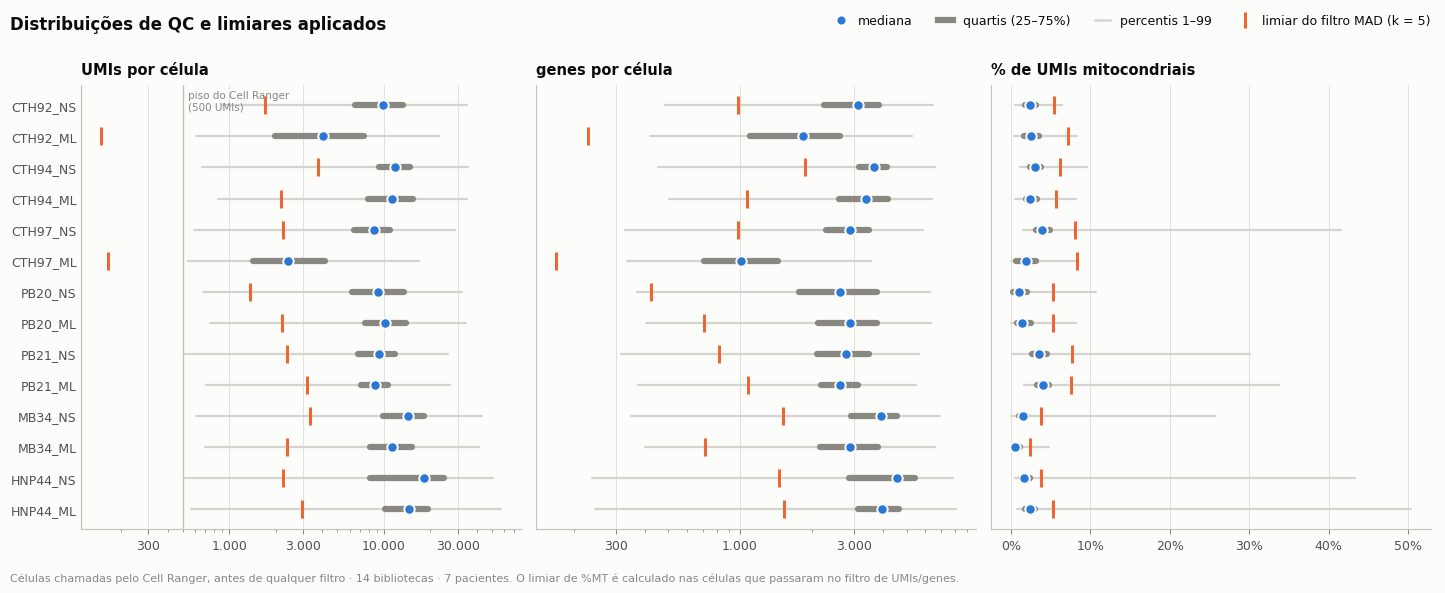

In [6]:
flags = pd.concat([res["flags"][lib].assign(library_id=lib).rename_axis("barcode").reset_index()
                   for lib in LIBS], ignore_index=True)

metricas = [("total_counts", "UMIs por célula", "umis_limiar_inferior", True),
            ("n_genes_by_counts", "genes por célula", "genes_limiar_inferior", True),
            ("pct_counts_mt", "% de UMIs mitocondriais", "mt_limiar_superior", False)]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 5.6), sharey=True)
y = np.arange(len(LIBS))[::-1]
quant_rows = []
for ax, (col, titulo, lim_col, logx) in zip(axes, metricas):
    for yi, lib in zip(y, LIBS):
        v = flags.loc[flags["library_id"] == lib, col].to_numpy()
        q01, q25, q50, q75, q99 = np.percentile(v, [1, 25, 50, 75, 99])
        quant_rows.append({"library_id": lib, "metrica": col, "p01": q01, "p25": q25, "p50": q50,
                           "p75": q75, "p99": q99, "limiar": limits.loc[lib, lim_col]})
        ax.plot([q01, q99], [yi, yi], color=plotting.CONTEXT, lw=1.6, zorder=1, solid_capstyle="round")
        ax.plot([q25, q75], [yi, yi], color=INK["muted"], lw=4.5, zorder=2, solid_capstyle="round")
        ax.plot(q50, yi, "o", ms=7.5, mfc=plotting.ACCENT, mec=INK["surface"], mew=1.4, zorder=4)
        ax.plot(limits.loc[lib, lim_col], yi, marker="|", ms=13, mew=2.2,
                color=plotting.CATEGORICAL[1], zorder=3, ls="")
    if logx:
        ax.set_xscale("log")
        ax.set_xticks([300, 1000, 3000, 10000, 30000] if col == "total_counts" else [300, 1000, 3000])
        ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.n(v)))
    else:
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 0) + "%"))
    ax.set_title(titulo, fontsize=10.5)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].axvline(500, color=INK["axis"], lw=1, zorder=0)
axes[0].annotate("piso do Cell Ranger\n(500 UMIs)", (500, 1.0), xycoords=("data", "axes fraction"),
                 textcoords="offset points", xytext=(4, -4), ha="left", va="top", fontsize=7.5,
                 color=INK["muted"])
axes[0].set_yticks(y)
axes[0].set_yticklabels(LIBS)
handles = [
    mpl.lines.Line2D([], [], marker="o", ls="", ms=7, mfc=plotting.ACCENT, mec=INK["surface"], mew=1.2, label="mediana"),
    mpl.lines.Line2D([], [], color=INK["muted"], lw=4.5, label="quartis (25–75%)"),
    mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=1.8, label="percentis 1–99"),
    mpl.lines.Line2D([], [], marker="|", ls="", ms=12, mew=2.2, color=plotting.CATEGORICAL[1], label="limiar do filtro MAD (k = 5)"),
]
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.legend(handles=handles, loc="upper right", ncol=4, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Distribuições de QC e limiares aplicados", x=0.01, y=0.985, ha="left",
             fontsize=12, fontweight="bold")
plotting.note(fig, f"Células chamadas pelo Cell Ranger, antes de qualquer filtro · {plotting.N_DESIGN}. "
                   "O limiar de %MT é calculado nas células que passaram no filtro de UMIs/genes.")
plotting.savefig(fig, NB, "qc_e_limiares", description="Distribuições de QC por biblioteca e limiares do filtro MAD",
                 data=pd.DataFrame(quant_rows), data_index=False)
plt.show()

In [7]:
abaixo_piso = limits.index[limits["umis_limiar_inferior"] < 500].tolist()
sem_corte = steps.index[steps["apos_contagem_genes"] == steps["cellranger"]].tolist()
print(f"limiar inferior de UMIs: de {F.n(limits['umis_limiar_inferior'].min())} a "
      f"{F.n(limits['umis_limiar_inferior'].max())}; abaixo do piso de 500 UMIs do Cell Ranger em "
      f"{len(abaixo_piso)} bibliotecas: {abaixo_piso}")
print(f"bibliotecas em que o filtro de UMIs/genes não removeu nenhuma célula: {sem_corte}")
print(f"limiar superior de %MT: de {F.f(limits['mt_limiar_superior'].min(), 1)}% a "
      f"{F.f(limits['mt_limiar_superior'].max(), 1)}%")
print(f"células com %MT > 8 que permanecem (flag criado, não aplicado): "
      f"{F.n(steps['mt_acima_8pct_nao_aplicado'].sum())}")

limiar inferior de UMIs: de 149 a 3.761; abaixo do piso de 500 UMIs do Cell Ranger em 2 bibliotecas: ['CTH92_ML', 'CTH97_ML']
bibliotecas em que o filtro de UMIs/genes não removeu nenhuma célula: ['CTH92_ML']
limiar superior de %MT: de 2,4% a 8,4%
células com %MT > 8 que permanecem (flag criado, não aplicado): 10


**Leitura.** O filtro é relativo à própria biblioteca. Onde a distribuição
de UMIs é larga, a MAD é grande e o limiar inferior cai abaixo do piso de 500
UMIs que o Cell Ranger já impõe — nessas bibliotecas o filtro de contagem
não tem o que cortar, e as células de menor conteúdo passam todas. O filtro
de %MT, ao contrário, é apertado em todas. A02 examina o que são as células
de baixa contagem que ficam.

## 3. Ressequenciamento: Scrublet

In [8]:
limpos, scr_rows, scr_cells = {}, [], []
for lib in LIBS:
    a = res["adatas"][lib]
    s = qc.run_original_scrublet(a)
    a.obs["doublet_score"] = s["scores"]
    a.obs["predicted_doublet"] = s["predicted"]
    scr_cells.append(pd.DataFrame({"library_id": lib, "barcode": a.obs_names,
                                   "doublet_score": s["scores"], "predicted_doublet": s["predicted"]}))
    limpos[lib] = a[~a.obs["predicted_doublet"]].copy()
    esperada = qc.expected_multiplet_rate(a.n_obs)
    scr_rows.append({
        "library_id": lib, "entrada": a.n_obs, "threshold_automatico": s["threshold"],
        "threshold_falhou": s["threshold_falhou"], "doublets_chamados": int(s["predicted"].sum()),
        "frac_chamada": float(s["predicted"].mean()), "saida": limpos[lib].n_obs,
        "taxa_esperada_10x": esperada, "doublets_esperados_10x": esperada * a.n_obs,
        "score_mediano_observado": s["obs_mediana"], "score_mediano_simulado": s["sim_mediana"],
        "simulados_acima_do_threshold": s["sim_acima_do_threshold"],
    })
scrub = pd.DataFrame(scr_rows).set_index("library_id")
io.save_table(scrub, NB, "scrublet_original", description="Scrublet com os parâmetros originais, por biblioteca")
F.styler(scrub[["entrada", "threshold_automatico", "doublets_chamados", "frac_chamada",
                "doublets_esperados_10x", "taxa_esperada_10x", "score_mediano_simulado",
                "simulados_acima_do_threshold"]],
         {"entrada": F.n, "threshold_automatico": lambda v: F.f(v, 3), "doublets_chamados": F.n,
          "frac_chamada": lambda v: F.pct(v, 2), "doublets_esperados_10x": lambda v: F.f(v, 0),
          "taxa_esperada_10x": F.pct, "score_mediano_simulado": lambda v: F.f(v, 3),
          "simulados_acima_do_threshold": F.pct})

,entrada,threshold_automatico,doublets_chamados,frac_chamada,doublets_esperados_10x,taxa_esperada_10x,score_mediano_simulado,simulados_acima_do_threshold
library_id,,,,,,,,
CTH92_NS,812,"0,363",3,"0,37%",5,"0,6%","0,110","0,6%"
CTH92_ML,1.538,"0,356",7,"0,46%",19,"1,2%","0,142","0,7%"
CTH94_NS,5.579,"0,598",3,"0,05%",249,"4,5%","0,162","1,0%"
CTH94_ML,500,"0,305",1,"0,20%",2,"0,4%","0,097","3,7%"
CTH97_NS,1.517,"0,429",4,"0,26%",18,"1,2%","0,122","1,5%"
CTH97_ML,4.696,"0,578",0,"0,00%",176,"3,8%","0,140","0,4%"
PB20_NS,602,"0,245",10,"1,66%",3,"0,5%","0,107","4,6%"
PB20_ML,781,"0,357",4,"0,51%",5,"0,6%","0,110","1,4%"
PB21_NS,3.666,"0,545",1,"0,03%",108,"2,9%","0,162","0,8%"


In [9]:
tot_in, tot_cham = scrub["entrada"].sum(), scrub["doublets_chamados"].sum()
tot_esp = scrub["doublets_esperados_10x"].sum()
zero = scrub.index[scrub["doublets_chamados"] == 0].tolist()
print(f"Scrublet removeu {F.n(tot_cham)} de {F.n(tot_in)} células ({F.pct(tot_cham / tot_in, 2)}); "
      f"{len(zero)} bibliotecas sem nenhuma remoção: {zero}")
print(f"esperado pela taxa de multipletos do 10x (0,8% por 1.000 células): ~{F.n(tot_esp)} "
      f"({F.pct(tot_esp / tot_in, 1)}); pelo parâmetro declarado de 6%: ~{F.n(0.06 * tot_in)}")
print(f"fração dos doublets SIMULADOS que fica acima do threshold automático: mediana "
      f"{F.pct(scrub['simulados_acima_do_threshold'].median())} "
      f"(de {F.pct(scrub['simulados_acima_do_threshold'].min())} a "
      f"{F.pct(scrub['simulados_acima_do_threshold'].max())})")
print(f"corrida antiga, para comparação: {F.n(sum(config.OLD_N_AFTER_MAD.values()) - sum(config.OLD_N_AFTER_SCRUBLET.values()))} "
      f"de {F.n(sum(config.OLD_N_AFTER_MAD.values()))} células removidas")

Scrublet removeu 62 de 35.126 células (0,18%); 2 bibliotecas sem nenhuma remoção: ['CTH97_ML', 'PB21_ML']
esperado pela taxa de multipletos do 10x (0,8% por 1.000 células): ~1.554 (4,4%); pelo parâmetro declarado de 6%: ~2.108
fração dos doublets SIMULADOS que fica acima do threshold automático: mediana 1,0% (de 0,2% a 8,5%)
corrida antiga, para comparação: 38 de 34.969 células removidas


**Leitura.** O comportamento da corrida antiga se repete. O threshold
automático cai acima de quase todos os doublets que o próprio Scrublet
simula: se ele mal detecta os doublets que ele mesmo fabricou, não detecta
os reais. A etapa, como configurada, é praticamente inócua. Isso não diz
quantos doublets existem — só que este teste não os enxerga; A03 trata da
pergunta de fundo.

In [10]:
log.add("MAJOR", "Scrublet com threshold automático",
        "a detecção de doublets remove quase nada, como na corrida antiga",
        evidence=f"{F.n(tot_cham)} de {F.n(tot_in)} células removidas ({F.pct(tot_cham / tot_in, 2)}), "
                 f"contra ~{F.n(tot_esp)} esperadas pela taxa do 10x; {len(zero)} bibliotecas sem "
                 f"remoção; só {F.pct(scrub['simulados_acima_do_threshold'].median())} (mediana) dos "
                 "doublets simulados ficam acima do threshold automático",
        impact="doublets heterotípicos remanescentes seguem no objeto; a etapa não serve de "
               "evidência nem a favor nem contra a hipótese de excesso de doublets",
        recommendation="calibrar o threshold pela taxa esperada por biblioteca e tratar os "
                       "marcados como análise de sensibilidade (A03)")

## 4. Etapa por etapa, corrida antiga × ressequenciamento

In [11]:
etapas = pd.DataFrame({
    "cellranger_antiga": pd.Series(config.OLD_N_RAW), "cellranger_nova": steps["cellranger"],
    "contagem_genes_antiga": pd.Series(config.OLD_N_AFTER_COMBINED), "contagem_genes_nova": steps["apos_contagem_genes"],
    "mt_antiga": pd.Series(config.OLD_N_AFTER_MAD), "mt_nova": steps["apos_mt"],
    "scrublet_antiga": pd.Series(config.OLD_N_AFTER_SCRUBLET), "scrublet_nova": scrub["saida"],
}).reindex(LIBS)
etapas.loc["TOTAL"] = etapas.sum()
etapas["mantidas_antiga"] = etapas["scrublet_antiga"] / etapas["cellranger_antiga"]
etapas["mantidas_nova"] = etapas["scrublet_nova"] / etapas["cellranger_nova"]
io.save_table(etapas, NB, "celulas_por_etapa", description="Células após cada etapa, corrida antiga × ressequenciamento")
F.styler(etapas, {**{c: F.n for c in etapas.columns if not c.startswith("mantidas")},
                  "mantidas_antiga": F.pct, "mantidas_nova": F.pct})

,cellranger_antiga,cellranger_nova,contagem_genes_antiga,contagem_genes_nova,mt_antiga,mt_nova,scrublet_antiga,scrublet_nova,mantidas_antiga,mantidas_nova
CTH92_NS,847,851,825,825,812,812,809,809,"95,5%","95,1%"
CTH92_ML,1.562,1.570,1.562,1.570,1.527,1.538,1.523,1.531,"97,5%","97,5%"
CTH94_NS,5.981,6.090,5.671,5.691,5.558,5.579,5.558,5.576,"92,9%","91,6%"
CTH94_ML,546,547,520,520,499,500,496,499,"90,8%","91,2%"
CTH97_NS,1.603,1.628,1.528,1.537,1.506,1.517,1.502,1.513,"93,7%","92,9%"
CTH97_ML,4.695,4.737,4.695,4.736,4.657,4.696,4.657,4.696,"99,2%","99,1%"
PB20_NS,637,635,613,609,606,602,604,592,"94,8%","93,2%"
PB20_ML,838,841,794,798,777,781,777,777,"92,7%","92,4%"
PB21_NS,3.919,4.266,3.664,3.710,3.626,3.666,3.625,3.665,"92,5%","85,9%"
PB21_ML,11.247,11.374,10.798,10.811,10.619,10.629,10.617,10.629,"94,4%","93,4%"


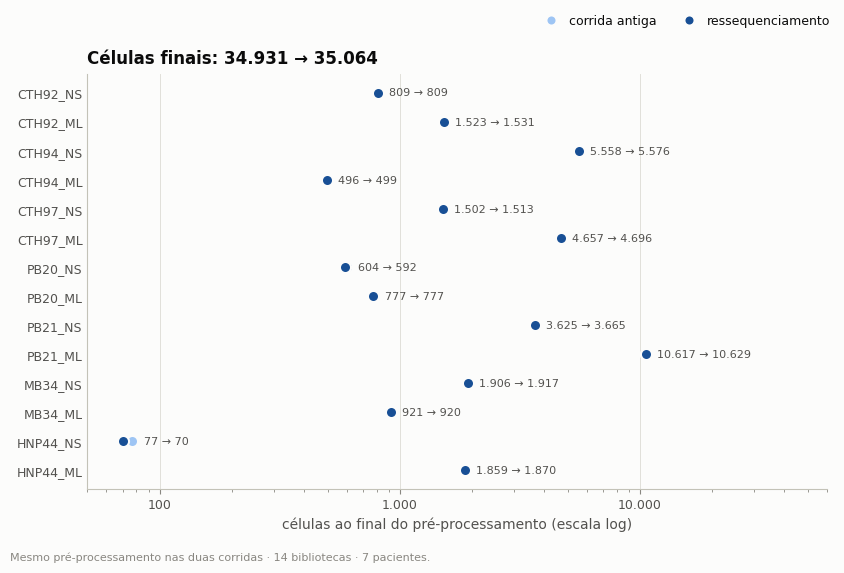

total: Cell Ranger 37.161 → 37.898; após filtros 34.931 → 35.064; fração mantida 94,0% → 92,5%
bibliotecas com menos de 200 células ao final: ['HNP44_NS'] (70)


In [12]:
fig, ax = plt.subplots(figsize=(8.4, 5.4))
fin = etapas.drop(index="TOTAL")
plotting.dumbbell(ax, fin["scrublet_antiga"], fin["scrublet_nova"], labels=LIBS, log=True,
                  xlabel="células ao final do pré-processamento (escala log)", legend=False,
                  value_fmt=lambda b, a: f"{F.n(b)} → {F.n(a)}")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.n(v)))
ax.set_xlim(50, 60000)
ax.set_title(f"Células finais: {F.n(etapas.loc['TOTAL', 'scrublet_antiga'])} → "
             f"{F.n(etapas.loc['TOTAL', 'scrublet_nova'])}")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(handles=plotting.old_new_handles(), loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
plotting.note(fig, f"Mesmo pré-processamento nas duas corridas · {plotting.N_DESIGN}.")
plotting.savefig(fig, NB, "celulas_finais", description="Células ao final do pré-processamento, antiga → nova",
                 data=fin[["scrublet_antiga", "scrublet_nova"]])
plt.show()

t = etapas.loc["TOTAL"]
print(f"total: Cell Ranger {F.n(t['cellranger_antiga'])} → {F.n(t['cellranger_nova'])}; após filtros "
      f"{F.n(t['scrublet_antiga'])} → {F.n(t['scrublet_nova'])}; fração mantida "
      f"{F.pct(t['mantidas_antiga'])} → {F.pct(t['mantidas_nova'])}")
pequenas = fin.index[fin["scrublet_nova"] < 200].tolist()
print(f"bibliotecas com menos de 200 células ao final: {pequenas} "
      f"({', '.join(F.n(fin.loc[l, 'scrublet_nova']) for l in pequenas)})")

O ressequenciamento chega ao fim do pré-processamento com praticamente o
mesmo número de células da corrida antiga, biblioteca por biblioteca. O
desbalanço se mantém, e a biblioteca não estimulada de HNP44 continua com
poucas dezenas de células.

In [13]:
frac_pb21 = fin.loc[["PB21_NS", "PB21_ML"], "scrublet_nova"].sum() / fin["scrublet_nova"].sum()
log.add("MAJOR", "desbalanço entre bibliotecas",
        "o desbalanço da corrida antiga se repete",
        evidence=f"de {F.n(fin['scrublet_nova'].min())} ({fin['scrublet_nova'].idxmin()}) a "
                 f"{F.n(fin['scrublet_nova'].max())} células ({fin['scrublet_nova'].idxmax()}): "
                 f"{F.x(fin['scrublet_nova'].max() / fin['scrublet_nova'].min(), 0)}; PB21 soma "
                 f"{F.pct(frac_pb21, 0)} das células finais",
        impact="clustering e HVGs dominados pelas bibliotecas grandes; HNP44_NS não sustenta "
               "composição nem pseudobulk",
        recommendation="estatística no nível de biblioteca/paciente; excluir HNP44_NS de "
                       "composição e pseudobulk, como já decidido para a corrida antiga")
log.add("MINOR", "filtro MAD de UMIs e genes",
        "em parte das bibliotecas o limiar inferior do filtro fica abaixo do piso do Cell Ranger e não corta nada",
        evidence=f"limiar de UMIs abaixo de 500 em {len(abaixo_piso)} bibliotecas "
                 f"({', '.join(abaixo_piso)}); nenhuma célula removida por UMIs/genes em "
                 f"{', '.join(sem_corte) if sem_corte else 'nenhuma biblioteca'}",
        impact="nessas bibliotecas todas as células de baixa contagem (logo acima de 500 UMIs) "
               "seguem para a integração",
        recommendation="avaliar um piso absoluto de UMIs/genes (A02)")
log.add("INFO", "flag mt_outlier (%MT > 8)",
        "o corte de 8% de mitocondrial é calculado mas não aplicado, como no original",
        evidence=f"{F.n(steps['mt_acima_8pct_nao_aplicado'].sum())} células com %MT > 8 permanecem; o "
                 f"filtro MAD já corta entre {F.f(limits['mt_limiar_superior'].min(), 1)}% e "
                 f"{F.f(limits['mt_limiar_superior'].max(), 1)}%",
        impact="nenhum relevante: o limiar MAD de %MT é mais estrito que 8% em quase todas as bibliotecas",
        recommendation="manter como está")

## 5. Gravação

* um h5ad por biblioteca, no mesmo formato de `data/new/` (índice de genes em
  Ensembl, `doublet_score`, `predicted_doublet`, `preprocessing_stats`), para
  que o `processing.ipynb` original rode sobre o ressequenciamento trocando só
  a pasta;
* a tabela de todas as células chamadas pelo Cell Ranger com a etapa em que
  cada uma saiu;
* em quantas células cada gene é detectado por biblioteca, depois do filtro —
  é o que define a interseção de genes da integração.

In [14]:
for lib in LIBS:
    io.save_data(limpos[lib], f"{NB}/new", lib,
                 description=f"{lib}: células após filtro MAD e Scrublet (formato de data/new)")

sc_all = pd.concat(scr_cells, ignore_index=True)
celulas = flags.merge(sc_all, on=["library_id", "barcode"], how="left")
celulas["predicted_doublet"] = celulas["predicted_doublet"].fillna(False).astype(bool)
celulas["mantida"] = celulas["passou_mad"] & ~celulas["predicted_doublet"]
celulas["etapa_de_saida"] = np.select(
    [celulas["fora_contagem"] | celulas["fora_genes"], celulas["fora_mt"], celulas["predicted_doublet"]],
    ["UMIs/genes", "%MT", "Scrublet"], default="mantida")
assert celulas.groupby("library_id")["mantida"].sum().reindex(LIBS).eq(scrub["saida"]).all()
io.save_data(celulas, NB, "celulas_qc",
             description="Todas as células do Cell Ranger: métricas de QC, flags e etapa de saída")

ref = io.reference_features()
det = pd.DataFrame(0, index=ref["gene_id"], columns=LIBS, dtype=np.int32)
for lib in LIBS:
    a = res["adatas"][lib]                       # pós-MAD, pré-Scrublet: é aqui que o original filtra genes
    det.loc[a.var_names, lib] = a.var["n_cells"].to_numpy()
det.insert(0, "gene_name", ref["gene_name"].to_numpy())
io.save_data(det.reset_index(), NB, "genes_por_biblioteca",
             description="Células com detecção de cada gene por biblioteca, após o filtro MAD")

print("células por etapa de saída:")
print(celulas["etapa_de_saida"].value_counts().map(F.n).to_string())
print(f"\ngenes mantidos por biblioteca (≥ 1 célula): de {F.n((det[LIBS] > 0).sum().min())} a "
      f"{F.n((det[LIBS] > 0).sum().max())}; em todas as 14: {F.n((det[LIBS] > 0).all(axis=1).sum())}; "
      f"em ao menos uma: {F.n((det[LIBS] > 0).any(axis=1).sum())}")

células por etapa de saída:
etapa_de_saida
mantida       35.064
UMIs/genes     2.183
%MT              589
Scrublet          62

genes mantidos por biblioteca (≥ 1 célula): de 22.650 a 31.273; em todas as 14: 18.852; em ao menos uma: 33.836


## Problemas e conclusão

In [15]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       2
MINOR       1
INFO        2


severity,location,problem,evidence,impact,recommendation
MAJOR,Scrublet com threshold automático,"a detecção de doublets remove quase nada, como na corrida antiga","62 de 35.126 células removidas (0,18%), contra ~1.554 esperadas pela taxa do 10x; 2 bibliotecas sem remoção; só 1,0% (mediana) dos doublets simulados ficam acima do threshold automático",doublets heterotípicos remanescentes seguem no objeto; a etapa não serve de evidência nem a favor nem contra a hipótese de excesso de doublets,calibrar o threshold pela taxa esperada por biblioteca e tratar os marcados como análise de sensibilidade (A03)
MAJOR,desbalanço entre bibliotecas,o desbalanço da corrida antiga se repete,de 70 (HNP44_NS) a 10.629 células (PB21_ML): 152×; PB21 soma 41% das células finais,clustering e HVGs dominados pelas bibliotecas grandes; HNP44_NS não sustenta composição nem pseudobulk,"estatística no nível de biblioteca/paciente; excluir HNP44_NS de composição e pseudobulk, como já decidido para a corrida antiga"
MINOR,filtro MAD de UMIs e genes,em parte das bibliotecas o limiar inferior do filtro fica abaixo do piso do Cell Ranger e não corta nada,"limiar de UMIs abaixo de 500 em 2 bibliotecas (CTH92_ML, CTH97_ML); nenhuma célula removida por UMIs/genes em CTH92_ML",nessas bibliotecas todas as células de baixa contagem (logo acima de 500 UMIs) seguem para a integração,avaliar um piso absoluto de UMIs/genes (A02)
INFO,réplica do pré-processamento,[verificado] a réplica reproduz exatamente o notebook original nos dados antigos,"14/14 bibliotecas com as mesmas contagens após filtro de contagem/genes, filtro de %MT e Scrublet (total 34.931 células = 34.931 do original)","as diferenças entre corridas vistas a seguir vêm do dado, não do código",nenhuma
INFO,flag mt_outlier (%MT > 8),"o corte de 8% de mitocondrial é calculado mas não aplicado, como no original","10 células com %MT > 8 permanecem; o filtro MAD já corta entre 2,4% e 8,4%",nenhum relevante: o limiar MAD de %MT é mais estrito que 8% em quase todas as bibliotecas,manter como está


## Conclusão

O pré-processamento original, validado contra seus próprios números, produz
no ressequenciamento praticamente o mesmo conjunto de células da corrida
antiga. Os dois comportamentos que já chamavam atenção se repetem: o filtro
de contagem não corta nada onde a distribuição é larga, e o Scrublet com
threshold automático não remove quase ninguém.

A linha principal segue com este resultado. Se algo mais deveria ser feito
antes da integração é a pergunta de A02; os doublets, de A03.

In [16]:
feitos = io.manifest()
feitos = feitos[feitos["stage"].str.startswith(NB)][["stage", "name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

25 artefatos gravados por este notebook:
                   stage                 name    kind
    A01_preprocessamento validacao_da_replica   table
    A01_preprocessamento         limiares_mad   table
    A01_preprocessamento    fig_qc_e_limiares  figure
    A01_preprocessamento    fig_qc_e_limiares   table
    A01_preprocessamento    scrublet_original   table
    A01_preprocessamento    celulas_por_etapa   table
    A01_preprocessamento   fig_celulas_finais  figure
    A01_preprocessamento   fig_celulas_finais   table
A01_preprocessamento/new             CTH92_NS    h5ad
A01_preprocessamento/new             CTH92_ML    h5ad
A01_preprocessamento/new             CTH94_NS    h5ad
A01_preprocessamento/new             CTH94_ML    h5ad
A01_preprocessamento/new             CTH97_NS    h5ad
A01_preprocessamento/new             CTH97_ML    h5ad
A01_preprocessamento/new              PB20_NS    h5ad
A01_preprocessamento/new              PB20_ML    h5ad
A01_preprocessamento/new              PB2